In [1]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/survival-detection/maritime_train.csv
/kaggle/input/survival-detection/maritime_sample_submission.csv
/kaggle/input/survival-detection/maritime_test.csv


# Importing Libraries

In [2]:
import warnings
warnings.filterwarnings("ignore")
warnings.filterwarnings("ignore", category=UserWarning)
import matplotlib.pyplot as plt



import numpy as np 
import pandas as pd 
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV



In [3]:
train=pd.read_csv('/kaggle/input/survival-detection/maritime_train.csv')
test=pd.read_csv('/kaggle/input/survival-detection/maritime_test.csv')
sample=pd.read_csv('/kaggle/input/survival-detection/maritime_sample_submission.csv')

In [4]:
df=pd.read_csv('/kaggle/input/survival-detection/maritime_train.csv')

In [5]:
df.head()

,PassengerId,TicketTier,PassengerName,Gender,Age,RelativesAboard,ParentsChildren,CLass,TicketCost,Berth,BoardingPort,FamilySize,Singleton,FarePerPerson,Title,Outcome
0,338.376107,0.977533,"Partner, Mr. Austen",male,NaN,0.005991,-0.024062,113043,29.104891,C124,S,1,1,25.906873,Mr,0
1,732.225160,2.016456,"Berriman, Mr. William John",male,21.574386,0.091114,-0.021340,28425,11.033567,NaN,S,1,1,10.939094,Mr,0
2,391.314100,2.998448,"Tikkanen, Mr. Juho",male,33.490756,-0.072885,-0.021702,STON/O 2. 3101293,2.234540,NaN,S,1,1,4.065968,Mr,0
3,724.550481,3.045488,"Hansen, Mr. Henrik Juul",male,25.200171,0.913680,0.032986,350025,10.958320,NaN,S,2,0,3.733784,Mr,0
4,810.994274,3.004710,"Andersson, Miss. Ebba Iris Alfrida",female,5.839590,4.009691,1.956266,347082,33.765343,NaN,S,7,0,3.325612,Miss,0


In [6]:
df.shape

(712, 16)

In [7]:
test.shape

(179, 15)

# Descriptive Statistics

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PassengerId,712.0,448.089668,256.347351,-19.969283,222.160559,455.043258,671.639433,905.400989
TicketTier,712.0,2.333755,0.826466,0.893173,1.954529,2.954504,3.006993,3.108531
Age,515.0,29.783025,14.605177,-1.128370,20.666161,28.374231,38.707210,79.849115
RelativesAboard,712.0,0.555223,1.174990,-0.148789,-0.016907,0.040156,0.967004,8.027245
ParentsChildren,712.0,0.378523,0.791899,-0.115958,-0.020213,0.017184,0.082670,6.045675
TicketCost,712.0,32.456248,52.079443,-3.982686,8.380745,14.833240,30.775352,514.074158
FamilySize,712.0,1.932584,1.682525,1.000000,1.000000,1.000000,2.000000,11.000000
Singleton,712.0,0.602528,0.489719,0.000000,0.000000,1.000000,1.000000,1.000000
FarePerPerson,712.0,20.043894,38.109959,-4.526815,6.596378,9.272521,18.980591,512.004226
Outcome,712.0,0.376404,0.484824,0.000000,0.000000,0.000000,1.000000,1.000000


* here, we can clearly see the features like Age, RelativesAboard, ParentsChildren, TicketCost, FamilySize, FarePerPerson seems skewed/possible have some outliers..
* Other features seems to be fairly distributed

In [9]:
test.describe().T

,count,mean,std,min,25%,50%,75%,max
PassengerId,179.0,438.029509,259.255724,9.802956,222.561008,427.571285,650.396799,899.233973
TicketTier,179.0,2.223348,0.877169,0.931608,1.053243,2.933747,3.004097,3.113545
Age,130.0,29.832722,14.429340,0.814432,19.604957,28.783827,37.764562,70.985271
RelativesAboard,179.0,0.403391,0.735023,-0.103505,-0.012059,0.024096,0.978520,4.037946
ParentsChildren,179.0,0.383128,0.862530,-0.105106,-0.022372,0.006931,0.103609,5.031118
TicketCost,179.0,30.764293,39.570427,0.880742,9.180750,15.403314,32.760887,262.644423
FamilySize,179.0,1.793296,1.301149,1.000000,1.000000,1.000000,2.000000,7.000000
Singleton,179.0,0.603352,0.490574,0.000000,0.000000,1.000000,1.000000,1.000000
FarePerPerson,179.0,19.048765,24.507250,0.078029,6.805145,9.328162,26.281589,221.311523


# Columns Data type and Non-Null Info

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 712 entries, 0 to 711
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   PassengerId      712 non-null    float64
 1   TicketTier       712 non-null    float64
 2   PassengerName    712 non-null    object 
 3   Gender           712 non-null    object 
 4   Age              515 non-null    float64
 5   RelativesAboard  712 non-null    float64
 6   ParentsChildren  712 non-null    float64
 7   CLass            712 non-null    object 
 8   TicketCost       712 non-null    float64
 9   Berth            159 non-null    object 
 10  BoardingPort     710 non-null    object 
 11  FamilySize       712 non-null    int64  
 12  Singleton        712 non-null    int64  
 13  FarePerPerson    712 non-null    float64
 14  Title            712 non-null    object 
 15  Outcome          712 non-null    int64  
dtypes: float64(7), int64(3), object(6)
memory usage: 89.1+ KB


In [11]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 179 entries, 0 to 178
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   PassengerId      179 non-null    float64
 1   TicketTier       179 non-null    float64
 2   PassengerName    179 non-null    object 
 3   Gender           179 non-null    object 
 4   Age              130 non-null    float64
 5   RelativesAboard  179 non-null    float64
 6   ParentsChildren  179 non-null    float64
 7   CLass            179 non-null    object 
 8   TicketCost       179 non-null    float64
 9   Berth            45 non-null     object 
 10  BoardingPort     179 non-null    object 
 11  FamilySize       179 non-null    int64  
 12  Singleton        179 non-null    int64  
 13  FarePerPerson    179 non-null    float64
 14  Title            179 non-null    object 
dtypes: float64(7), int64(2), object(6)
memory usage: 21.1+ KB


some features like Age, Berth, BoardingPort seems to have null values ... Let's check how much null values they hold


# Checking Missing Values

In [12]:
df.isnull().sum().sort_values(ascending=False)

Berth              553
Age                197
BoardingPort         2
PassengerId          0
Gender               0
RelativesAboard      0
PassengerName        0
TicketTier           0
CLass                0
ParentsChildren      0
TicketCost           0
FamilySize           0
Singleton            0
FarePerPerson        0
Title                0
Outcome              0
dtype: int64

In [13]:
test.isnull().sum().sort_values(ascending=False)

Berth              134
Age                 49
TicketTier           0
PassengerName        0
Gender               0
RelativesAboard      0
PassengerId          0
ParentsChildren      0
CLass                0
TicketCost           0
BoardingPort         0
FamilySize           0
Singleton            0
FarePerPerson        0
Title                0
dtype: int64

## Missing Percentage

In [14]:
missing_per=df.isnull().sum().sort_values(ascending=False)/df.shape[0] *100
missing_per

Berth              77.668539
Age                27.668539
BoardingPort        0.280899
PassengerId         0.000000
Gender              0.000000
RelativesAboard     0.000000
PassengerName       0.000000
TicketTier          0.000000
CLass               0.000000
ParentsChildren     0.000000
TicketCost          0.000000
FamilySize          0.000000
Singleton           0.000000
FarePerPerson       0.000000
Title               0.000000
Outcome             0.000000
dtype: float64

In [15]:
missing_per=test.isnull().sum().sort_values(ascending=False)/test.shape[0] *100
missing_per

Berth              74.860335
Age                27.374302
TicketTier          0.000000
PassengerName       0.000000
Gender              0.000000
RelativesAboard     0.000000
PassengerId         0.000000
ParentsChildren     0.000000
CLass               0.000000
TicketCost          0.000000
BoardingPort        0.000000
FamilySize          0.000000
Singleton           0.000000
FarePerPerson       0.000000
Title               0.000000
dtype: float64

Berth has around 78 percent of missing values in training set and 75 percent in test. It seems unreliable and model will feel difficulty with this much amount of missing values. Hence, we'll drop the features with more than 70 percent of null values

In [16]:
df.drop(['Berth'], axis=1,inplace=True)

In [17]:
test.drop(['Berth'], axis=1,inplace=True)

We'll impute the null values of Age and BoardingPort Later by analysing their values

# Unique Values for each feature

In [18]:
for col in df.columns:
  print(f'{col} has {df[col].nunique()} unique values \n {'---'* 20}')

PassengerId has 712 unique values 
 ------------------------------------------------------------
TicketTier has 712 unique values 
 ------------------------------------------------------------
PassengerName has 712 unique values 
 ------------------------------------------------------------
Gender has 2 unique values 
 ------------------------------------------------------------
Age has 515 unique values 
 ------------------------------------------------------------
RelativesAboard has 712 unique values 
 ------------------------------------------------------------
ParentsChildren has 712 unique values 
 ------------------------------------------------------------
CLass has 558 unique values 
 ------------------------------------------------------------
TicketCost has 712 unique values 
 ------------------------------------------------------------
BoardingPort has 3 unique values 
 ------------------------------------------------------------
FamilySize has 9 unique values 
 -----------

In [19]:
for col in test.columns:
  print(f'{col} has {test[col].nunique()} unique values \n {'---'* 20}')

PassengerId has 179 unique values 
 ------------------------------------------------------------
TicketTier has 179 unique values 
 ------------------------------------------------------------
PassengerName has 179 unique values 
 ------------------------------------------------------------
Gender has 2 unique values 
 ------------------------------------------------------------
Age has 130 unique values 
 ------------------------------------------------------------
RelativesAboard has 179 unique values 
 ------------------------------------------------------------
ParentsChildren has 179 unique values 
 ------------------------------------------------------------
CLass has 169 unique values 
 ------------------------------------------------------------
TicketCost has 179 unique values 
 ------------------------------------------------------------
BoardingPort has 3 unique values 
 ------------------------------------------------------------
FamilySize has 7 unique values 
 -----------

* features like PassengerId, PassengerName, TicketTier, TicketCost, FarePerPerson, ParentsChildren, RelativesAboard has all unique values.
* We should drop the Identifiers like PassengerID, PassengerName
* Other high Cardinality features like TicketTier, TicketCost, FarePerPerson, Age etc ... needs to look further before dropping them blindly.

In [20]:
df.shape

(712, 15)

In [21]:
test.shape

(179, 14)

# Visualisation of Age Feature

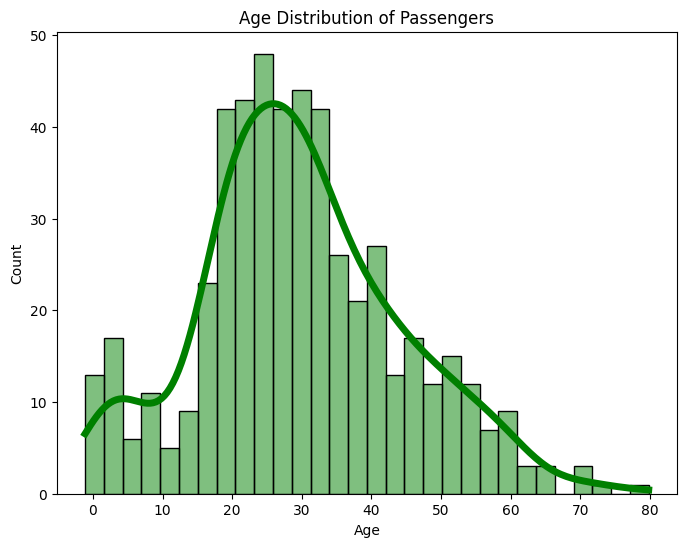

In [22]:
plt.figure(figsize=(8,6))
sns.histplot(data=df, x="Age", bins=30, kde=True, color="green", line_kws={'lw':5} )

plt.title("Age Distribution of Passengers")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()


In [23]:
print(f'Negatives Ages :\n{df.Age[df.Age <= 0 ]},\n{'---'*20}\nMissing Ages {df.Age.isnull().sum()}')

Negatives Ages :
402   -0.040543
532   -1.128370
Name: Age, dtype: float64,
------------------------------------------------------------
Missing Ages 197


In [24]:
df.loc[df["Age"] <= 0, "Age"] = np.nan
df.Age.isnull().sum()

np.int64(199)

* We can see the plot is right skewed and hence we'll try to impute null with median Age 
* We'll replace the negative ages with null as no negative age exists in real so it's more like a noise in data 

In [25]:
for dataset in [df, test]:
    dataset["Age"] = dataset.groupby(
        ["Title", "Gender"]
    )["Age"].transform(lambda x: x.fillna(x.median()))


In [26]:
df.Age.isna().sum()

np.int64(0)

In [27]:
test.Age.isna().sum()

np.int64(0)

# Vusualisation of BoardingPort

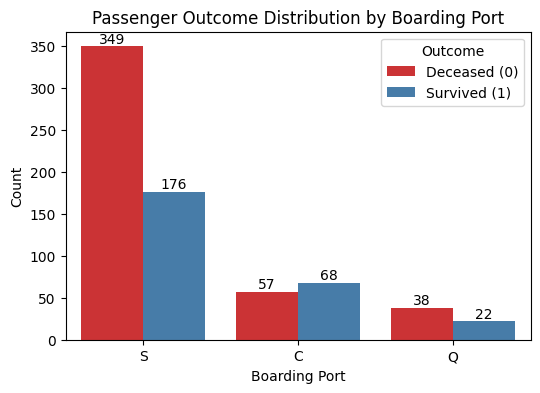

In [28]:
plt.figure(figsize=(6,4))

ax = sns.countplot(data=df, x="BoardingPort", hue="Outcome", palette="Set1")

for container in ax.containers:
    ax.bar_label(container)

plt.title("Passenger Outcome Distribution by Boarding Port")
plt.xlabel("Boarding Port")
plt.ylabel("Count")
plt.legend(title="Outcome", labels=["Deceased (0)", "Survived (1)"])
plt.show()


In [29]:
df.BoardingPort.fillna(df.BoardingPort.mode()[0], inplace=True)

In [30]:
df.BoardingPort.isnull().sum()

np.int64(0)

# Duplicate Check

In [31]:
df.duplicated().sum()

np.int64(0)

# Correlation Heatmap  
Heatmap to see the correlation of independent feature with the dependent one

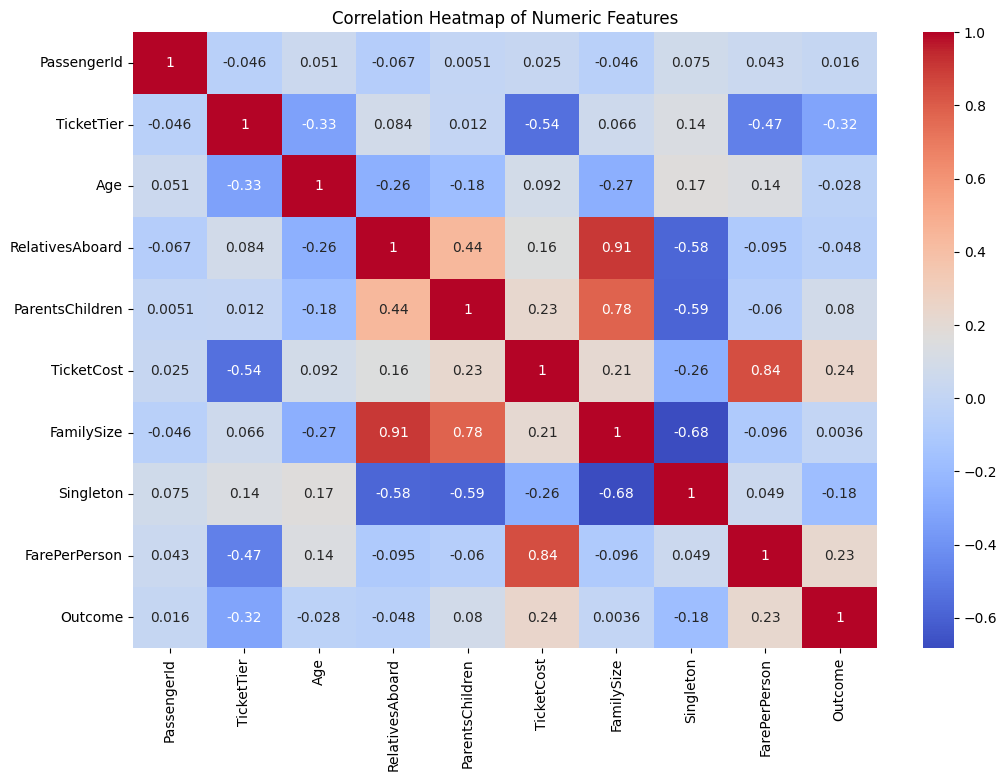

In [32]:
plt.figure(figsize=(12,8))
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap of Numeric Features")
plt.show()


from the heatmap, we can clearly see the feature FamilySize is highly correlated with RelativesAboard, ParentsChildren. So we'll drop the two by keeping only FamilySize only

In [33]:
df.drop(["RelativesAboard", "ParentsChildren"], axis=1, inplace=True)

In [34]:
test.drop(["RelativesAboard", "ParentsChildren"], axis=1, inplace=True)

In [35]:
df.shape

(712, 13)

In [36]:
test.shape

(179, 12)

# Outliers Detection

In [37]:
def outlier_func(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3-Q1
                      
    upper_limit = Q3 + (1.5*IQR)
    lower_limit = Q1 - (1.5*IQR)
    outlier_count = ((df[col] < lower_limit) | (df[col] > upper_limit)).sum()
    
    return {
        "lower_limit": round(float(lower_limit),2),
        "upper_limit": round(float(upper_limit),2),
        "outlier_count": int(outlier_count)
    }



In [38]:
for col in df.select_dtypes(include=np.number).columns:
    print(f"{col} → {outlier_func(df, col)} \n{'---'*50}")


PassengerId → {'lower_limit': -452.06, 'upper_limit': 1345.86, 'outlier_count': 0} 
------------------------------------------------------------------------------------------------------------------------------------------------------
TicketTier → {'lower_limit': 0.38, 'upper_limit': 4.59, 'outlier_count': 0} 
------------------------------------------------------------------------------------------------------------------------------------------------------
Age → {'lower_limit': 1.62, 'upper_limit': 55.5, 'outlier_count': 39} 
------------------------------------------------------------------------------------------------------------------------------------------------------
TicketCost → {'lower_limit': -25.21, 'upper_limit': 64.37, 'outlier_count': 95} 
------------------------------------------------------------------------------------------------------------------------------------------------------
FamilySize → {'lower_limit': -0.5, 'upper_limit': 3.5, 'outlier_count': 77} 
------

In [39]:
df.head()

,PassengerId,TicketTier,PassengerName,Gender,Age,CLass,TicketCost,BoardingPort,FamilySize,Singleton,FarePerPerson,Title,Outcome
0,338.376107,0.977533,"Partner, Mr. Austen",male,29.591412,113043,29.104891,S,1,1,25.906873,Mr,0
1,732.225160,2.016456,"Berriman, Mr. William John",male,21.574386,28425,11.033567,S,1,1,10.939094,Mr,0
2,391.314100,2.998448,"Tikkanen, Mr. Juho",male,33.490756,STON/O 2. 3101293,2.234540,S,1,1,4.065968,Mr,0
3,724.550481,3.045488,"Hansen, Mr. Henrik Juul",male,25.200171,350025,10.958320,S,2,0,3.733784,Mr,0
4,810.994274,3.004710,"Andersson, Miss. Ebba Iris Alfrida",female,5.839590,347082,33.765343,S,7,0,3.325612,Miss,0


In [40]:
df.columns

Index(['PassengerId', 'TicketTier', 'PassengerName', 'Gender', 'Age', 'CLass',
       'TicketCost', 'BoardingPort', 'FamilySize', 'Singleton',
       'FarePerPerson', 'Title', 'Outcome'],
      dtype='object')

# Values for feature TicketTier

It should have values like 1,2,3 ..... but it holds the floats so let's round it to int.

In [41]:
df["TicketTier"] = df["TicketTier"].round().astype(int)

In [42]:
test["TicketTier"] = test["TicketTier"].round().astype(int)

In [43]:
df.TicketTier.unique()

array([1, 2, 3])

In [44]:
test.TicketTier.unique()

array([3, 2, 1])

# Feature Engineering

In [45]:
df["FamilyName"] = (
    df["PassengerName"]
    .str.split(",", expand=True)[0]
    .str.lower()
    .str.strip()
    .str.replace(r"[^\w\s]", "", regex=True)
)

test["FamilyName"] = (
    test["PassengerName"]
    .str.split(",", expand=True)[0]
    .str.lower()
    .str.strip()
    .str.replace(r"[^\w\s]", "", regex=True)
)



In [46]:
df.FamilyName.isnull().sum() , test.FamilyName.isnull().sum()

(np.int64(0), np.int64(0))

In [47]:
from sklearn.model_selection import StratifiedKFold
import numpy as np

df["FamilySurvivalRate"] = np.nan

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for train_idx, val_idx in skf.split(df, df["Outcome"]):
    train_fold = df.iloc[train_idx]
    val_fold = df.iloc[val_idx]

    family_survival = train_fold.groupby("FamilyName")["Outcome"].mean()

    df.loc[val_idx, "FamilySurvivalRate"] = (
        val_fold["FamilyName"].map(family_survival)
    )

global_survival = df["Outcome"].mean()
df["FamilySurvivalRate"].fillna(global_survival, inplace=True)


In [48]:
family_survival_full = df.groupby("FamilyName")["Outcome"].mean()

test["FamilySurvivalRate"] = test["FamilyName"].map(family_survival_full)
test["FamilySurvivalRate"].fillna(global_survival, inplace=True)


In [49]:
df["FamilySurvivalRate"].isnull().sum(), test["FamilySurvivalRate"].isnull().sum()

(np.int64(0), np.int64(0))

In [50]:
df.drop(['PassengerId', 'PassengerName', "FamilyName"], inplace=True, axis=1)

In [51]:
test.drop(['PassengerId', 'PassengerName',"FamilyName"], inplace=True, axis=1)

In [52]:
df["Gender_Tier"] = df["Gender"].astype(str) + "_" + df["TicketTier"].astype(str)
test["Gender_Tier"] = test["Gender"].astype(str) + "_" + test["TicketTier"].astype(str)

df["RichWoman"] = ((df["Gender"]=="female") & (df["TicketTier"]==1)).astype(int)
test["RichWoman"] = ((test["Gender"]=="female") & (test["TicketTier"]==1)).astype(int)

df["PoorMan"] = ((df["Gender"]=="male") & (df["TicketTier"]==3)).astype(int)
test["PoorMan"] = ((test["Gender"]=="male") & (test["TicketTier"]==3)).astype(int)


In [53]:
df.select_dtypes(include="number").corr()

,TicketTier,Age,TicketCost,FamilySize,Singleton,FarePerPerson,Outcome,FamilySurvivalRate,RichWoman,PoorMan
TicketTier,1.000000,-0.331027,-0.545603,0.066748,0.133766,-0.475785,-0.321750,-0.209432,-0.532993,0.660348
Age,-0.331027,1.000000,0.091597,-0.267863,0.165948,0.141328,-0.028484,0.044609,0.144740,-0.131757
TicketCost,-0.545603,0.091597,1.000000,0.214216,-0.257199,0.843807,0.242913,0.076389,0.499435,-0.307593
FamilySize,0.066748,-0.267863,0.214216,1.000000,-0.682916,-0.095877,0.003565,-0.085778,0.007629,-0.086920
Singleton,0.133766,0.165948,-0.257199,-0.682916,1.000000,0.048789,-0.180542,-0.149152,-0.136655,0.255018
FarePerPerson,-0.475785,0.141328,0.843807,-0.095877,0.048789,1.000000,0.226831,0.028258,0.445804,-0.242209
Outcome,-0.321750,-0.028484,0.242913,0.003565,-0.180542,0.226831,1.000000,0.191576,0.395807,-0.394065
FamilySurvivalRate,-0.209432,0.044609,0.076389,-0.085778,-0.149152,0.028258,0.191576,1.000000,0.086683,-0.140807
RichWoman,-0.532993,0.144740,0.499435,0.007629,-0.136655,0.445804,0.395807,0.086683,1.000000,-0.268192
PoorMan,0.660348,-0.131757,-0.307593,-0.086920,0.255018,-0.242209,-0.394065,-0.140807,-0.268192,1.000000


## TicketCost and FarePerPerson has high correlation 
So let's test which has more power to contribute to Target

In [54]:
from sklearn.feature_selection import mutual_info_classif

X = df[["TicketCost","FarePerPerson"]]
y = df["Outcome"]
mutual_info_classif(X, y)

array([0.04996766, 0.03895118])

we'll try to keep TicketCost and will drop FarePerPerson


In [55]:
df.drop("FarePerPerson", axis=1, inplace=True)

In [56]:
test.drop("FarePerPerson", axis=1, inplace=True)

In [57]:
df['TicketCost']=np.log(df.TicketCost)
test['TicketCost']=np.log(test.TicketCost)

In [58]:
df.TicketCost.replace(np.nan, df.TicketCost.median(skipna=True), inplace=True)
test.TicketCost.replace(np.nan, test.TicketCost.median(skipna=True), inplace=True)

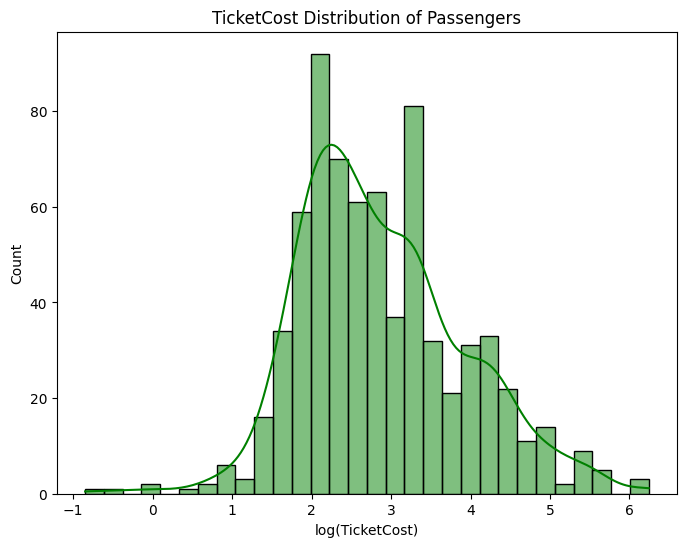

In [59]:
plt.figure(figsize=(8,6))
sns.histplot(data=df, x="TicketCost", bins=30, kde=True, color="green" )

plt.title("TicketCost Distribution of Passengers")
plt.xlabel("log(TicketCost)")
plt.ylabel("Count")
plt.show()


In [60]:
outlier_func(df,"TicketCost")

{'lower_limit': 0.22, 'upper_limit': 5.35, 'outlier_count': 21}

In [61]:
df.shape, test.shape

((712, 14), (179, 13))

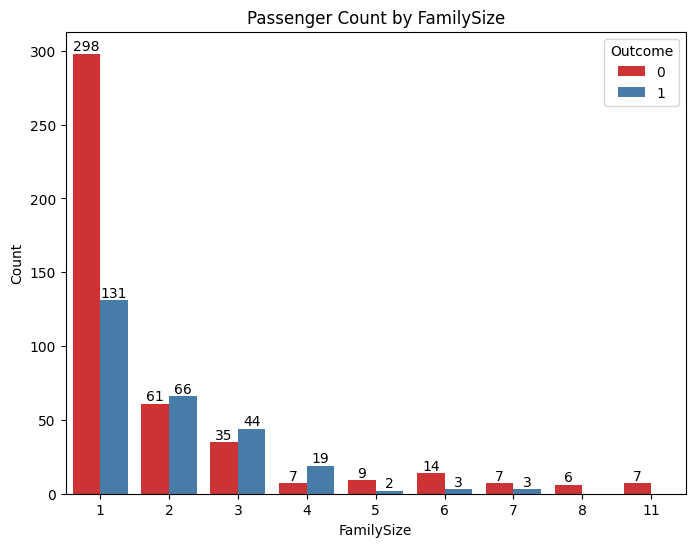

In [62]:
plt.figure(figsize=(8,6))
ax=sns.countplot(data=df, x="FamilySize",hue="Outcome", palette="Set1")
for container in ax.containers:
    ax.bar_label(container)

plt.title("Passenger Count by FamilySize")
plt.xlabel("FamilySize")
plt.ylabel("Count")
plt.show()

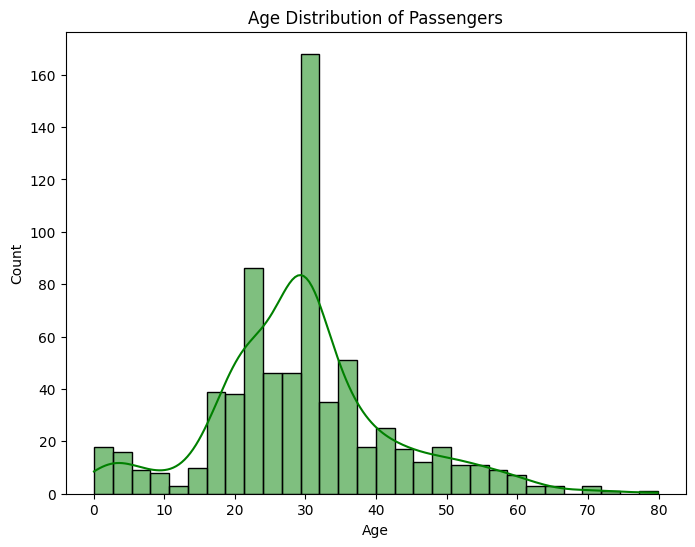

In [63]:
plt.figure(figsize=(8,6))
sns.histplot(data=df, x="Age", bins=30, kde=True, color="green" )

plt.title("Age Distribution of Passengers")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()


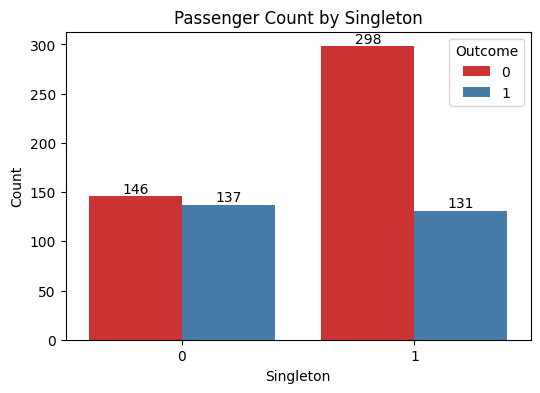

In [64]:
plt.figure(figsize=(6,4))
ax=sns.countplot(data=df, x="Singleton",hue="Outcome", palette="Set1")
for container in ax.containers:
    ax.bar_label(container)

plt.title("Passenger Count by Singleton")
plt.xlabel("Singleton")
plt.ylabel("Count")
plt.show()

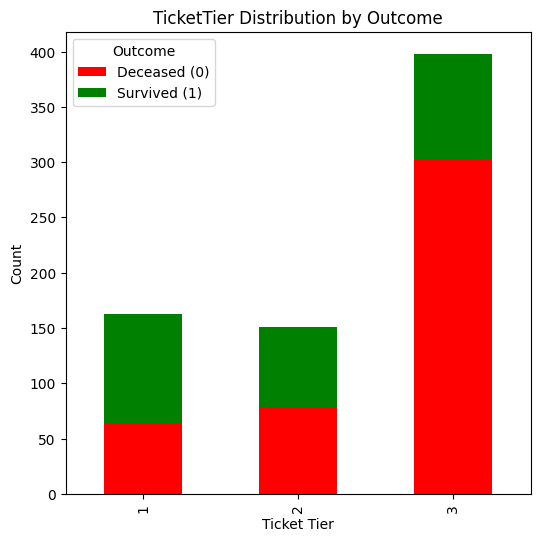

In [65]:
tier_outcome = pd.crosstab(df["TicketTier"], df["Outcome"])

tier_outcome.plot(kind="bar", stacked=True, color=["red","green"], figsize=(6,6))

plt.title("TicketTier Distribution by Outcome")
plt.xlabel("Ticket Tier")
plt.ylabel("Count")
plt.legend(title="Outcome", labels=["Deceased (0)", "Survived (1)"])
plt.show()

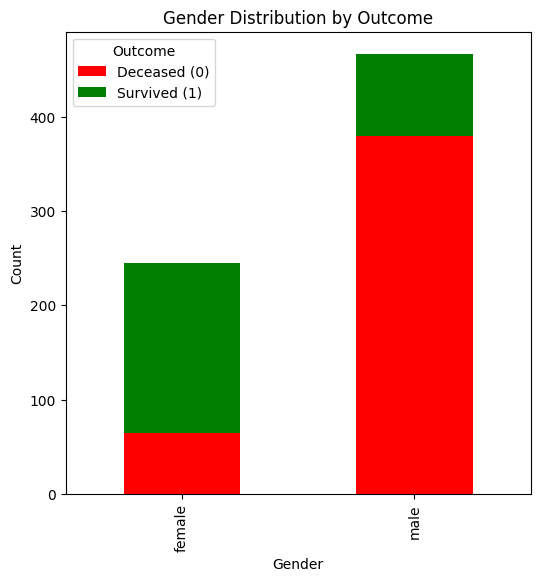

In [66]:
sex_outcome = pd.crosstab(df["Gender"], df["Outcome"])

sex_outcome.plot(kind="bar", stacked=True, color=["red","green"], figsize=(6,6))

plt.title("Gender Distribution by Outcome")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.legend(title="Outcome", labels=["Deceased (0)", "Survived (1)"])
plt.show()

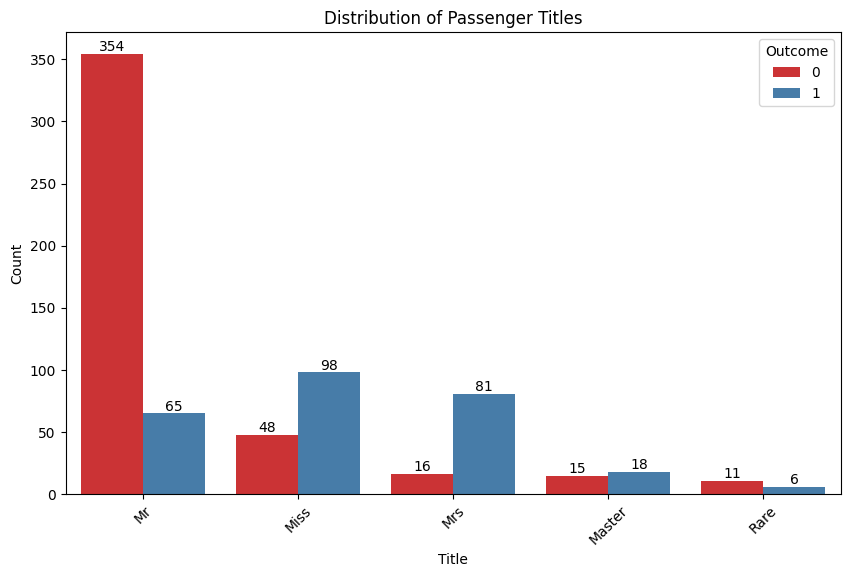

In [67]:

plt.figure(figsize=(10,6))
ax=sns.countplot(x="Title", data=df, order=df["Title"].value_counts().index, hue="Outcome", palette='Set1')
for container in ax.containers:
    ax.bar_label(container)

plt.title("Distribution of Passenger Titles")
plt.xlabel("Title")
plt.ylabel("Count")
plt.xticks(rotation=45) 
plt.show()


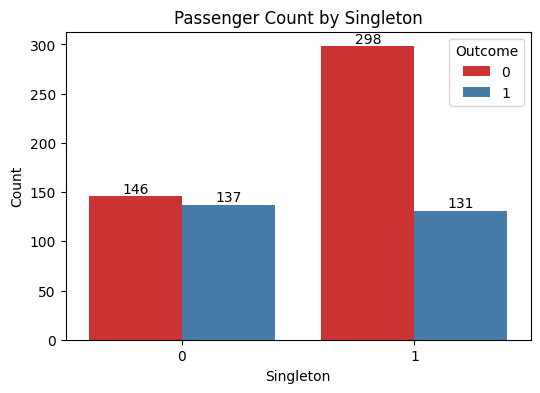

In [68]:
plt.figure(figsize=(6,4))
ax=sns.countplot(data=df, x="Singleton",hue="Outcome", palette="Set1")
for container in ax.containers:
    ax.bar_label(container)

plt.title("Passenger Count by Singleton")
plt.xlabel("Singleton")
plt.ylabel("Count")
plt.show()

In [69]:
df.columns

Index(['TicketTier', 'Gender', 'Age', 'CLass', 'TicketCost', 'BoardingPort',
       'FamilySize', 'Singleton', 'Title', 'Outcome', 'FamilySurvivalRate',
       'Gender_Tier', 'RichWoman', 'PoorMan'],
      dtype='object')

In [70]:
df.drop("CLass", axis=1, inplace=True)

In [71]:
test.drop("CLass", axis=1, inplace=True)

In [72]:
df.dtypes.sort_values(ascending=True)

TicketTier              int64
FamilySize              int64
Singleton               int64
Outcome                 int64
RichWoman               int64
PoorMan                 int64
Age                   float64
TicketCost            float64
FamilySurvivalRate    float64
Gender                 object
BoardingPort           object
Title                  object
Gender_Tier            object
dtype: object

In [73]:
test.dtypes.sort_values(ascending=True)

TicketTier              int64
FamilySize              int64
Singleton               int64
RichWoman               int64
PoorMan                 int64
Age                   float64
TicketCost            float64
FamilySurvivalRate    float64
Gender                 object
BoardingPort           object
Title                  object
Gender_Tier            object
dtype: object

In [74]:
df.shape, test.shape

((712, 13), (179, 12))

In [75]:
df.head()

,TicketTier,Gender,Age,TicketCost,BoardingPort,FamilySize,Singleton,Title,Outcome,FamilySurvivalRate,Gender_Tier,RichWoman,PoorMan
0,1,male,29.591412,3.370906,S,1,1,Mr,0,0.376404,male_1,0,0
1,2,male,21.574386,2.400942,S,1,1,Mr,0,0.376404,male_2,0,0
2,3,male,33.490756,0.804035,S,1,1,Mr,0,0.376404,male_3,0,1
3,3,male,25.200171,2.394099,S,2,0,Mr,0,0.376404,male_3,0,1
4,3,female,5.839590,3.519435,S,7,0,Miss,0,0.285714,female_3,0,0


In [76]:
categorical_features = ["Gender", "BoardingPort", "Title","Gender_Tier"]
numeric_features = ["Age", "TicketCost", "FamilySize","TicketTier","FamilySurvivalRate","Singleton","RichWoman","PoorMan"]

categorical_transformer = OneHotEncoder(handle_unknown="ignore")

numeric_transformer = StandardScaler()

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", categorical_transformer, categorical_features),
        ("num", numeric_transformer, numeric_features)
    ]
)



In [77]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_transformed = preprocessor.fit_transform(X)
X_transformed

array([[ 0.        ,  1.        ,  0.        , ...,  0.81220297,
        -0.33020337, -0.81220297],
       [ 0.        ,  1.        ,  0.        , ...,  0.81220297,
        -0.33020337, -0.81220297],
       [ 0.        ,  1.        ,  0.        , ...,  0.81220297,
        -0.33020337,  1.23121934],
       ...,
       [ 0.        ,  1.        ,  0.        , ..., -1.23121934,
        -0.33020337,  1.23121934],
       [ 1.        ,  0.        ,  0.        , ..., -1.23121934,
         3.02843665, -0.81220297],
       [ 0.        ,  1.        ,  0.        , ..., -1.23121934,
        -0.33020337, -0.81220297]])

In [78]:
model = LogisticRegression(max_iter=1000)
model.fit(X_transformed, y)

y_pred = model.predict(X_transformed)

In [79]:
scores = cross_val_score(model,X_transformed,y ,cv=5, scoring="accuracy")
print("Mean CV Accuracy:", scores.mean())

Mean CV Accuracy: 0.8230079779375554


In [80]:
param_grid = {
    'C': [ 0.01, 0.1, 1],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear', 'saga', 'lbfgs'],
    'class_weight': [None, 'balanced'],
    'max_iter': [1000, 2000]
}

log_reg = LogisticRegression()
grid_search_lg = GridSearchCV(log_reg, param_grid, cv=5, scoring='accuracy', n_jobs=-1, verbose=0)
grid_search_lg.fit(X_transformed, y)

print("Best Params:", grid_search_lg.best_params_)
print("Best CV Score:", grid_search_lg.best_score_)


Best Params: {'C': 1, 'class_weight': None, 'max_iter': 1000, 'penalty': 'l1', 'solver': 'liblinear'}
Best CV Score: 0.8328572835615088


In [81]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=4)

scores = cross_val_score(knn, X_transformed, y, cv=5, scoring="accuracy")
print("KNN CV Accuracy:", scores.mean())

KNN CV Accuracy: 0.8173840244262779


In [82]:
param_grid = {
    'n_neighbors': [3,4, 5, 7, 9],  
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'minkowski'] 
}


grid_search_knn = GridSearchCV(knn, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search_knn.fit(X_transformed, y)

print("Best Params:", grid_search_knn.best_params_)
print("Best CV Score:", grid_search_knn.best_score_)


Best Params: {'metric': 'euclidean', 'n_neighbors': 7, 'weights': 'distance'}
Best CV Score: 0.8244361272530286


In [83]:
rf= RandomForestClassifier(
        n_estimators=200, 
        max_depth=None, 
        random_state=42
    )


scores = cross_val_score(rf, X_transformed, y, cv=5, scoring="accuracy")
print("Random Forest CV Accuracy:", scores.mean())

Random Forest CV Accuracy: 0.8047473653107456


In [84]:
param_grid = {
    "n_estimators": [200, 500],
    "max_depth": [10, 20],
    "min_samples_split": [5, 10],
    "min_samples_leaf": [ 2, 4],
    "max_features": ["sqrt", "log2"],
    "bootstrap": [True, False],
    "class_weight": [None, "balanced"]
}

grid_search_rf = GridSearchCV(
    rf, param_grid, cv=5, scoring="accuracy", n_jobs=-1, verbose=0
)
grid_search_rf.fit(X_transformed, y)

print("Best params:", grid_search_rf.best_params_)
print("Best CV score:", grid_search_rf.best_score_)

Best params: {'bootstrap': False, 'class_weight': None, 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 500}
Best CV score: 0.8398601398601399


In [85]:
from xgboost import XGBClassifier

xgb= XGBClassifier(
        n_estimators=300, 
        learning_rate=0.05, 
        max_depth=4, 
        subsample=0.8, 
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss"
    )


scores = cross_val_score(xgb, X_transformed, y, cv=5, scoring="accuracy")
print("XGBoost CV Accuracy:", scores.mean())

XGBoost CV Accuracy: 0.810371318822023


In [86]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [200, 300],
    "max_depth": [3, 4],
    "learning_rate": [0.01, 0.05],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "min_child_weight": [1, 3],
    "reg_alpha": [0.01, 0.001],
    "reg_lambda": [1, 1.5]
}

grid_search_xgb = GridSearchCV(
    xgb, param_grid, cv=5, scoring="accuracy", n_jobs=-1,
)
grid_search_xgb.fit(X_transformed, y)

print("Best params:", grid_search_xgb.best_params_)
print("Best CV score:", grid_search_xgb.best_score_)

Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 4, 'min_child_weight': 1, 'n_estimators': 200, 'reg_alpha': 0.01, 'reg_lambda': 1, 'subsample': 0.8}
Best CV score: 0.8398404412488919


In [87]:
from catboost import CatBoostClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, GridSearchCV

cat = CatBoostClassifier(
        iterations=1200,          
        learning_rate=0.001,
        depth=6,                
        subsample=1.0,
        random_seed=42,
        eval_metric="Logloss",
        verbose=0                
    )


scores = cross_val_score(cat, X_transformed, y, cv=5, scoring="accuracy")
print("CatBoost CV Accuracy:", scores.mean())



CatBoost CV Accuracy: 0.8342164877376146


In [88]:
param_grid = {
    "iterations": [800, 1200],
    "depth": [ 4, 6],
    "learning_rate": [0.01, 0.001],
    "subsample": [0.8, 1.0],
    "l2_leaf_reg": [1, 3],  
    "border_count": [32, 64]
}

grid_search_cat = GridSearchCV(
    cat, param_grid, cv=5, scoring="accuracy", n_jobs=-1
)
grid_search_cat.fit(X_transformed, y)

print("Best params:", grid_search_cat.best_params_)
print("Best CV score:", grid_search_cat.best_score_)

Best params: {'border_count': 64, 'depth': 6, 'iterations': 1200, 'l2_leaf_reg': 1, 'learning_rate': 0.001, 'subsample': 1.0}
Best CV score: 0.8356249384418399


In [89]:
test_transformed = preprocessor.transform(test)
predictions = grid_search_cat.predict(test_transformed)


In [90]:
test2=pd.read_csv("/kaggle/input/survival-detection/maritime_test.csv")

In [91]:
submission = pd.DataFrame({
    "PassengerName": test2["PassengerName"], 
    "Outcome": predictions
})
submission.to_csv("submission.csv", index=False)

In [92]:
sample

,PassengerName,Outcome
0,"Moubarek, Master. Halim Gonios (""William George"")",0
1,"Kvillner, Mr. Johan Henrik Johannesson",0
2,"Alhomaki, Mr. Ilmari Rudolf",0
3,"Harper, Miss. Annie Jessie ""Nina""",0
4,"Nicola-Yarred, Miss. Jamila",0
...,...,...
174,"Kallio, Mr. Nikolai Erland",0
175,"Elias, Mr. Dibo",0
176,"Asplund, Mrs. Carl Oscar (Selma Augusta Emilia...",0
177,"Ilett, Miss. Bertha",0
